<a href="https://colab.research.google.com/github/mahapatramadhu-ops/python-/blob/main/regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import pandas as pd

In [11]:
df=pd.read_csv("/Student_Performance_Dataset-selected-columns.csv")

In [12]:
df.head()

,Student_ID,Age,Gender,Class,Study_Hours_Per_Day,Attendance_Percentage,Parental_Education,Internet_Access,Extracurricular_Activities,Math_Score
0,S0001,15,Male,12,1.0,65,Postgraduate,No,No,40
1,S0002,19,Female,9,1.6,58,Graduate,No,Yes,80
2,S0003,14,Female,12,3.6,64,High School,Yes,Yes,83
3,S0004,18,Female,9,5.5,68,Postgraduate,Yes,No,68
4,S0005,14,Male,10,5.0,80,High School,Yes,No,41


In [21]:
x = df.Study_Hours_Per_Day
y = df.Math_Score
print(x)
print(y)

0       1.0
1       1.6
2       3.6
3       5.5
4       5.0
       ... 
4995    4.0
4996    5.6
4997    2.3
4998    2.9
4999    2.0
Name: Study_Hours_Per_Day, Length: 5000, dtype: float64
0       40
1       80
2       83
3       68
4       41
        ..
4995    64
4996    44
4997    95
4998    66
4999    69
Name: Math_Score, Length: 5000, dtype: int64


In [25]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
x = df.Study_Hours_Per_Day .values.reshape(-1,1) # Added .values to ensure it's a NumPy array for reshape
y = df.Math_Score
m = LinearRegression()
m.fit(x,y)

a = m.intercept_
b = m.coef_[0]
print ("intercep = ", round(a,2))
print ("slope =", round(b,2))
print("equation: ")
print(f"marks = {round(a,2)}+ {round(b,2)}* Study Hours") # Corrected f-string
hours= int(input("enter numbers of hours:"))
predicted_marks =  m.predict([[hours]]) # Corrected to pass a 2D array for single prediction
print("\nPredicted marks =", round(predicted_marks[0],2))
if predicted_marks > 40: # Corrected variable name from Predicted_marks to predicted_marks
      print("result:pass")
else:
      print("result:fail")

intercep =  67.12
slope = 0.19
equation: 
marks = 67.12+ 0.19* Study Hours
enter numbers of hours:10

Predicted marks = 69.05
result:pass


intercep =  67.12
slope = 0.19
equation: 
marks = 67.12+ 0.19* Study Hours
enter numbers of hours:5

Predicted marks = 68.09


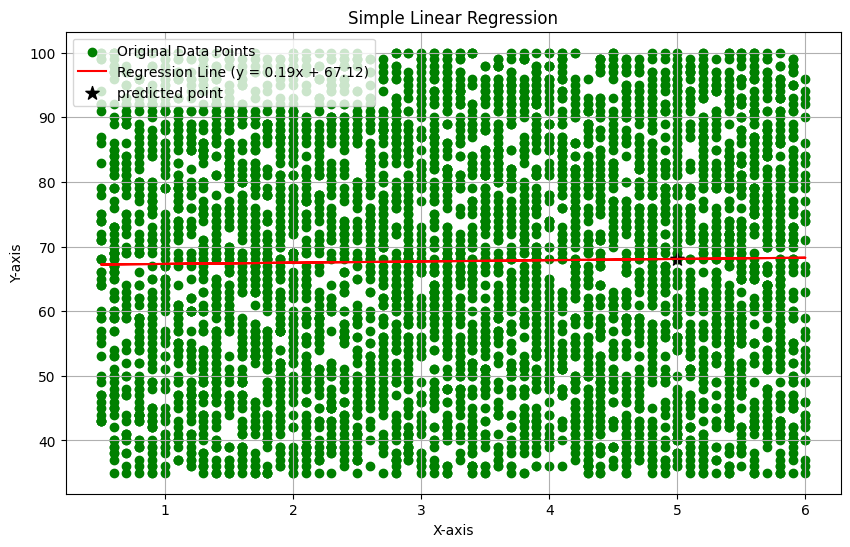

In [31]:
from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
x = df.Study_Hours_Per_Day .values.reshape(-1,1) # Added .values to ensure it's a NumPy array for reshape
y = df.Math_Score
m = LinearRegression()
m.fit(x,y)

a = m.intercept_
b = m.coef_[0]
print ("intercep = ", round(a,2))
print ("slope =", round(b,2))
print("equation: ")
print(f"marks = {round(a,2)}+ {round(b,2)}* Study Hours") # Corrected f-string
hours= int(input("enter numbers of hours:"))

predicted_marks =  m.predict([[hours]]) # Corrected to pass a 2D array for single prediction
print("\nPredicted marks =", round(predicted_marks[0],2))
plt.figure(figsize=(10, 6))
plt.scatter(x_np, y_np, color='green', label='Original Data Points')
plt.plot(x_np, y_predicted, color='red', label=f'Regression Line (y = {slope:.2f}x + {intercept:.2f})')
plt.scatter(hours,predicted_marks,color="black",s=100,marker="*",label="predicted point")
plt.xlabel('X-axis')
plt.ylabel('Y-axis')
plt.title('Simple Linear Regression')
plt.legend()
plt.grid(True)
plt.show()

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

# Define the target variable
y = df['Math_Score']

# Define the independent variables (features) for multiple regression
# Including numerical features: Study_Hours_Per_Day, Attendance_Percentage
# And categorical features: Gender, Parental_Education, Internet_Access, Extracurricular_Activities
features = [
    'Study_Hours_Per_Day',
    'Attendance_Percentage'
]
X = df[features]

# Identify categorical and numerical features for preprocessing
numerical_features = ['Study_Hours_Per_Day', 'Attendance_Percentage']

# Create a column transformer to apply OneHotEncoder to categorical features
# Numerical features will be passed through without transformation.
# Create a pipeline: preprocess the data then apply Linear Regression
multiple_regression_model = Pipeline(steps=[
    ('regressor', LinearRegression())
])

# Train the multiple regression model
multiple_regression_model.fit(X, y)

# Get the intercept and coefficients
intercept = multiple_regression_model.named_steps['regressor'].intercept_
coefficients = multiple_regression_model.named_steps['regressor'].coef_

print(f"\nMultiple Regression Model Intercept: {intercept:.2f}")
print("Multiple Regression Model Coefficients:")

# Get the names of the one-hot encoded features.
# Combine all feature names in the order they appear after preprocessing
all_feature_names = numerical_features

# Print each coefficient with its corresponding feature name
for feature_name, coef in zip(all_feature_names, coefficients):
    print(f"  {feature_name}: {coef:.2f}")

hours= int(input("enter numbers of hours:"))
attendance= float(input("enter attendane"))
predicted_marks =  m.predict([[hours],[attendance]]) # Corrected to pass a 2D array for single prediction
print("\nPredicted marks =", round(predicted_marks[0],2))



Multiple Regression Model Intercept: 66.08
Multiple Regression Model Coefficients:
  Study_Hours_Per_Day: 0.19
  Attendance_Percentage: 0.01
enter numbers of hours:5
enter attendane55

Predicted marks = 68.09


Intercept: 65.30118541070226
Coefficients: [0.29936679 0.02262946]


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


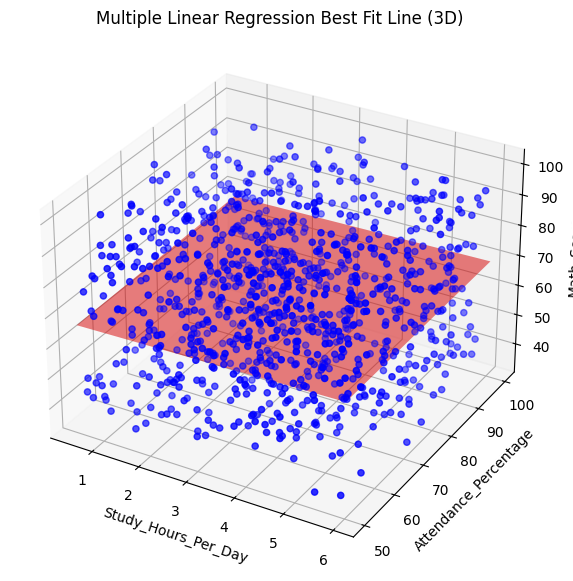

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x = df[['Study_Hours_Per_Day', 'Attendance_Percentage']]
y = df.Math_Score

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_test['Study_Hours_Per_Day'], X_test['Attendance_Percentage'],y_test, color='blue', label='Actual Data')

x1_range = np.linspace(X_test['Study_Hours_Per_Day'].min(), X_test['Study_Hours_Per_Day'].max(), 100)
x2_range = np.linspace(X_test['Attendance_Percentage'].min(), X_test['Attendance_Percentage'].max(), 100)
x1, x2 = np.meshgrid(x1_range, x2_range)

z = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)

ax.plot_surface(x1, x2, z, color='red', alpha=0.5, rstride=100, cstride=100)

ax.set_xlabel('Study_Hours_Per_Day')
ax.set_ylabel('Attendance_Percentage')
ax.set_zlabel('Math_Score')
ax.set_title('Multiple Linear Regression Best Fit Line (3D)')

plt.show()

In [54]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

y = df['Math_Score']

features = [
    'Study_Hours_Per_Day',
    'Attendance_Percentage'
]
X = df[features]

numerical_features = ['Study_Hours_Per_Day', 'Attendance_Percentage']
multiple_regression_model = Pipeline(steps=[
    ('regressor', LinearRegression())
])

multiple_regression_model.fit(X, y)

intercept = multiple_regression_model.named_steps['regressor'].intercept_
coefficients = multiple_regression_model.named_steps['regressor'].coef_

print(f"\nMultiple Regression Model Intercept: {intercept:.2f}")
print("Multiple Regression Model Coefficients:")

all_feature_names = numerical_features
for feature_name, coef in zip(all_feature_names, coefficients):
    print(f"  {feature_name}: {coef:.2f}")

hours= int(input("enter numbers of hours:"))
attendance= float(input("enter attendane"))
predicted_marks =  m.predict([[hours],[attendance]]) # Corrected to pass a 2D array for single prediction
print("\nPredicted marks =", round(predicted_marks[0],2))
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Grade")
plt.ylabel("Predicted Grade")
plt.title("Actual vs Predicted Grades")


Multiple Regression Model Intercept: 66.08
Multiple Regression Model Coefficients:
  Study_Hours_Per_Day: 0.19
  Attendance_Percentage: 0.01
enter numbers of hours:5
enter attendane55

Predicted marks = 68.09


NameError: name 'y_test' is not defined

<Figure size 800x600 with 0 Axes>